In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from numba import jit
import random

In [32]:
class cell:
    def __init__(self,index,init_clusters,parent,birth):
        '''Initializes cell attributes
        param:: index: cell index
        param:: clusters: count of n-clusters
        param:: x: plasmid trajectory in time 
        param:: t: time stamps for x
        param:: parent: parent cell
        param:: birth: birth time
        return:: None
        '''
        self.index=index
        self.init_clusters=init_clusters
        self.fin_clusters=[]
        self.x = []
        self.t = []
        self.parent = parent
        self.birth = birth

@jit
def find_tot_plasmids(y1,y2,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y2[0]+=y2[1]
    y1[1]=y1[0]
    y2[1]=y2[0]
    y_tot1 = np.dot(np.arange(1,max_size),y1[1:max_size])
    y_tot2 = np.dot(np.arange(1,max_size),y2[1:max_size])            
    y_tot = y_tot1+y_tot2
    y1[1]=0
    y2[1]=0
    return y1,y2,y_tot1,y_tot2,y_tot 

@jit
def pop_check(cells,T):
    b_filter = [x for x in cells if x.t[0] <= T]
    d_filter = [x for x in b_filter if x.t[-1] >T]
    return d_filter #N_pop


@jit
def hazards(y,c_idx,num_reax,N,y_totp,y_tot,beta,gamma,sigma,max_size):
    a =np.zeros(num_reax)                                     #reaction hazards 
    v=np.zeros([num_reax,max_size])                           #reaction vectors    
    a[0]=(k_tr*y_totp)/(1+K*y_tot/(s0*n))**n
    v[0,0] = 1
    a[1] = 0.5*beta*y[0]*(y[0]-1)
    v[1,0] = -2
    v[1,2] = 1

    if N>1:
        species_idx =np.zeros([2,num_reax])
        count=1
        for i in np.arange(1,N):   #plasmid recruitment
            count+=1
            a[count] = beta*y[0]*y[c_idx[i]]
            species_idx[:,count] = np.array([c_idx[i],0])
        rec_count=count
                
        for i in np.arange(1,N):   #cluster combination
            for j in np.arange(i,N):
                count+=1
                if i==j:
                    a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                else:
                    a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                species_idx[:,count] = [c_idx[i],c_idx[j]]
        cluster_count = count
            
        for i in np.arange(1,N): #plasmid shedding
            count+=1
            a[count] = sigma*y[c_idx[i]]*c_idx[i]
            species_idx[:,count] = np.array([c_idx[i],0])
                    
        for i in range(len(a)): #reaction vectors
            if i==0:                         #plasmid replication
                v[i,0] = 1
            elif i==1:                       #plasmid duplex formation
                v[i,0] = -2
                v[i,2] = 1
            elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                v[i,0] = -1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])+1] = 1
            elif (i>rec_count and i<=cluster_count):   #cluster combination
                if (int(species_idx[0,i])==int(species_idx[1,i])):
                    v[i,int(species_idx[0,i])] = -2
                else:
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[1,i])] = -1
                v[i,int(np.sum(species_idx[:,i]))] = 1
            else:                            #plasmid shedding         
                v[i,0] = 1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])-1] = 1   
    return a,v


@jit
def ssa(y0,x0,tau,beta,gamma,sigma,max_size):
    y=y0               #plasmid count count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot1=x0
    y_tot2 = 0
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    y_tot=y_tot1+y_tot2
    while t_y<tau:
        ############################### pole 1 ##################################
        dummy = y1[0]                                               
        y1[0] = 1
        c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state except possibly free plasmids
        y1[0] = dummy
        N1 = len(c_idx1)                                            #number of non-zero species
        num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)           #possible number of reactions given the system state 
        a1,v1 = hazards(y1,c_idx1,num_reax1,N1,y_tot1,y_tot,beta,gamma,sigma,max_size)     
        
        ############################### pole 2 ##################################
        dummy = y2[0]
        y2[0]=1
        c_idx2 = np.where(y2>0)[0]                                  
        y2[0]=dummy
        N2 = len(c_idx2)
        num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)  
        a2,v2 = hazards(y2,c_idx2,num_reax2,N2,y_tot2,y_tot,beta,gamma,sigma,max_size)

        a = np.append(a1,a2,axis=0)
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        sum_a=np.sum(a)
        cumsum_a=np.cumsum(a,axis=0)
        epsilon=np.random.uniform(0,1,2)
        j=np.min(np.where(epsilon[0]*sum_a<cumsum_a)) 
        t_f=(np.log(1/epsilon[1]))/sum_a
                     
        if t_y+t_f<tau:  
            t_y+=t_f 
            if (j==num_reax1+num_reax2):
                y2[0]+=1
                y1[0]-=1
            elif (j==num_reax1+num_reax2+1):
                y2[0]-=1
                y1[0]+=1
            elif (num_reax1<=j and j<num_reax1+num_reax2):
                y2+=v2[j-num_reax1,:]  
            else:
                y1+=v1[j,:]    
                
            y1,y2,y_tot1,y_tot2,y_tot = find_tot_plasmids(y1,y2,max_size)
            if (j==0 or j==num_reax1):
                x= np.append(x,y_tot)
                t_x =np.append(t_x,[t_y])
        else:
            t_y=tau
            x=np.append(x,x[-1])
            t_x =np.append(t_x,[t_y])  
    y = np.append(y1,y2,axis=0)
    return y,x,t_x

def pop_sim(Q,tau,beta,gamma,sigma,max_size,Nmax):
    cells =[]  #processed cells
    N=0  #cell index
    keep = 100  #keep number of living cells
    time_stamp = (np.log2(keep)+1)*60 +30 # approximate time "keep" number of cells are produced  
    check_cells = False
    pop_achieved = False
    while len(cells)<=Nmax:
        if len(cells)>2*keep:
            check_cells = True
            
        current = Q[0]
        y0 = current.init_clusters
        y0[1]=y0[0]
        x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
        y0[1]=0 
        div_time = tau+np.random.normal(0,1)
        if x0>0:
            yy,xx,tt = ssa(y0,x0,div_time,beta,gamma,sigma,max_size)
        else:
            yy = y0
            xx = np.array([0,0])
            tt = np.array([0,div_time])
       
        Q.pop(0)  #remove current cell from Q
        
        #update current cell
        current.fin_clusters = yy
        current.x = xx
        current.t = tt+current.birth   
        cells.extend([current])
        
        #generate daughter cells
        daughter1 = cell(N+1,np.append(yy[:max_size],np.zeros(max_size)),current.index,current.birth+div_time)
        daughter2 = cell(N+2,np.append(yy[max_size:],np.zeros(max_size)),current.index,current.birth+div_time)
        N+=2
        Q.extend([daughter1,daughter2])  #add daugthers to Q
        Q = sorted(Q, key=lambda x: x.birth, reverse=False) #sort Q wrt cell birth time
        
        if len(cells)%21==0:
            print(len(cells))    
        
    return cells,Q

In [33]:
tau = 60
k_tr = 2.73
K = 9.007936508
s0 = 13.58595
n = 2.5
x0=20
max_size=500
beta = 0.1 #plasmid recruitment rate constant
gamma = 1*beta #plasmid combination rate constant
sigma= 1*beta  #plasmid dissociation rate constant
rho = 0.1  #plasmid transfer rate constant

Nmax =2**11 #2**14
y0 = np.zeros(2*max_size)
y0[0]=x0

c= cell(0,y0,[],0)   #index,clusters,parent,birth
Q=[c]

In [34]:
cells, Q = pop_sim(Q,tau,beta,gamma,sigma,max_size,Nmax)
with open("test", "wb") as fp:   #Pickling
    pickle.dump(cells, fp)
#with open("test", "rb") as fp:   # Unpickling
#    load_cells = pickle.load(fp)

21
42
63
84
105
126
147
168
189
210
231
252
273
294
315
336
357
357
357
357
357
357
357
357
357
357
357
357
357
357
357
357
378
399
420
441
462
483
504
525
546
567
588
609
630
651
672
693
714
735
756
777
798
819
840
861
882
903
924
945
966
987
1008
1029
1050
1071
1092
1113
1134
1155
1176
1197
1218
1239
1260
1281
1302
1323
1344
1365
1386
1407
1428
1449
1470
1491
1512
1533
1554
1575
1596
1617
1638
1659
1680
1701
1722
1743
1764
1785
1806
1827
1848
1869
1890
1911
1932
1953
1974
1995
2016
2037


In [37]:
cells[-1].birth

654.253549213355

In [38]:
(np.log2(100)+1)*60 +30

488.63137138648347

IndexError: list index out of range

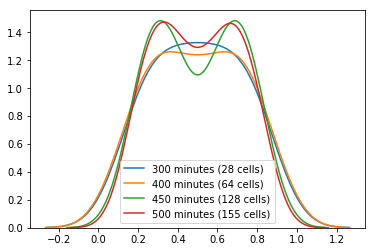

In [40]:
################ inheritance ratio #######################

#time_stamps = [400,500,600,700,800]
time_stamps = [300,400,450,500,550]

f=plt.figure()
for k in range(len(time_stamps)):
    gg = pop_check(cells,time_stamps[k])
    inheritance = np.zeros(len(gg))
    for i in range(len(gg)):
        parent = [x for x in cells if x.index == gg[i].parent]
        inheritance[i] =gg[i].x[0]/ parent[0].x[-1]
    sns.kdeplot(inheritance,label='%d minutes (%d cells)' %(time_stamps[k],len(gg)))
plt.xlabel('Inheritance ratio ($N_d/N_p$)')
plt.ylabel('PDF')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

In [45]:
parent[0].x[-1]

IndexError: list index out of range

IndexError: list index out of range

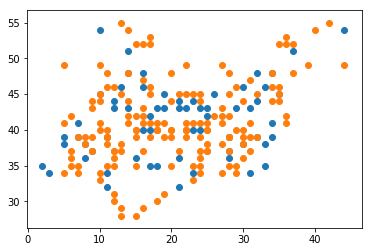

In [41]:
################ inheritance vs parent plasmid #######################

time_stamps = [400,500,600,700,800]
f=plt.figure()
for k in range(len(time_stamps)):
    gg = pop_check(cells,time_stamps[k])
    inherited = np.zeros(len(gg))
    parent_copy = np.zeros(len(gg))
    for i in range(len(gg)):
        parent = [x for x in cells if x.index == gg[i].parent]
        inherited[i] = gg[i].x[0]
        parent_copy[i]=parent[0].x[-1]
    plt.scatter(inherited,parent_copy,label='%d minutes (%d cells)' %(time_stamps[k],len(gg)))
plt.xlabel('Number of Inherited Plasmid ($N_d$)')
plt.ylabel('Parent Plasmid Copy Number ($N_p$)')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

Text(0, 0.5, 'PDF')

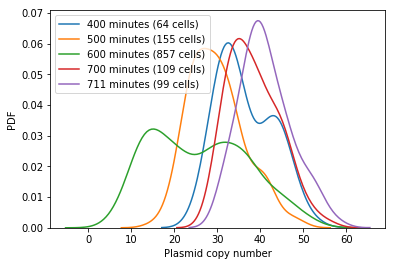

In [48]:
################ plasmid copy number #######################
################ instantaneous #######################

time_stamps = [400,500,600,700,711]
f=plt.figure()
for k in range(len(time_stamps)):
    gg = pop_check(cells,time_stamps[k])
    plasmid_count = np.zeros(len(gg))
    for i in range(len(gg)):
        idx = np.max(np.where(gg[i].t<time_stamps[k]))
        plasmid_count[i]=gg[i].x[idx]
    sns.kdeplot(plasmid_count,label='%d minutes (%d cells)' %(time_stamps[k],len(gg)))
plt.xlabel('Plasmid copy number')
plt.ylabel('PDF')

In [ ]:
################ plasmid copy number #######################
################ detected at end of cell cycle #######################

time_stamps = [400,500,600,700,800]
f=plt.figure()
for k in range(len(time_stamps)):
    gg = pop_check(cells,time_stamps[k])
    plasmid_count = np.zeros(len(gg))
    for i in range(len(gg)):
        plasmid_count[i]=gg[i].x[-1]
    sns.kdeplot(plasmid_count,label='%d minutes (%d cells)' %(time_stamps[k],len(gg)))
plt.xlabel('Plasmid copy number')
plt.ylabel('PDF')

In [ ]:
with open("cell_data", "rb") as fp:   # Unpickling
    cells = pickle.load(fp)


In [ ]:
cells_try = cells.copy()
rem_cells = [cells_try[1], cells_try[2]]

In [ ]:
new_cells = [x for x in cells_try if x not in rem_cells]

In [ ]:
new_cells[1].birth

In [ ]:
new_cells[0].birth

In [ ]:
cells[0].birth

In [ ]:
len(new_cells)

In [ ]:
cells_try = new_cells

In [ ]:
kk = random.sample(cells,1)

In [ ]:
kk[0].birth

In [ ]:
cells[0].birth

In [ ]:
gg = [x.parent for x in Q]

In [ ]:
gg

In [ ]:
ggg = list(set(gg))

In [ ]:
ggg

In [ ]:
len(gg)

In [ ]:
len(ggg)*2